Task 1

In [2]:
from google.colab import files
uploaded = files.upload()

Saving iris.csv.txt to iris.csv.txt


In [4]:
import pandas as pd

# 1. Load the file, telling pandas it is comma-separated
df = pd.read_csv("iris.csv.txt")

# 2. Check if it worked
print(df.shape)
print(df.head())

(150, 5)
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


Shape: (150, 5)
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Class counts:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Nulls:
 sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


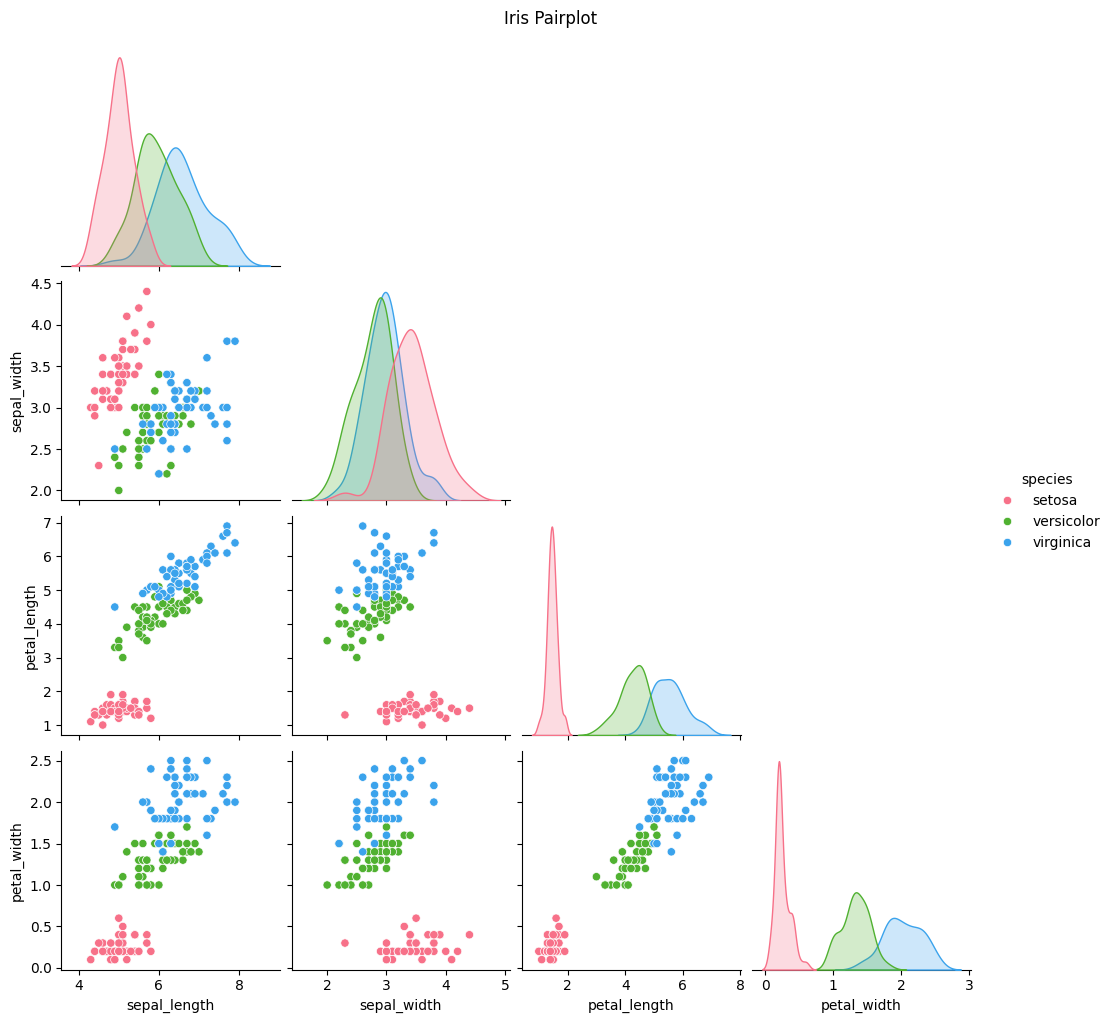

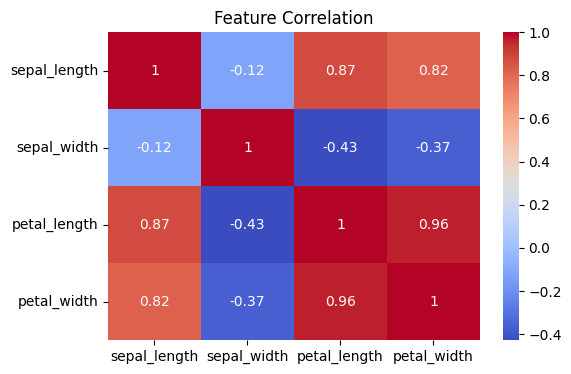


=== Benchmark Results ===
              Model  Accuracy  Precision  Recall  F1-Score
Logistic Regression    0.9333     0.9333  0.9333    0.9333
      Decision Tree    0.9333     0.9333  0.9333    0.9333

--- Logistic Regression — Classification Report ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


--- Decision Tree — Classification Report ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93

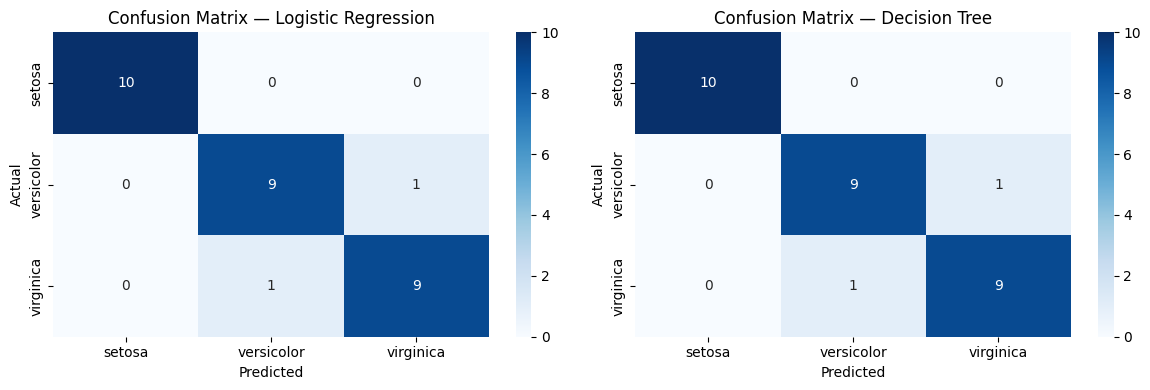

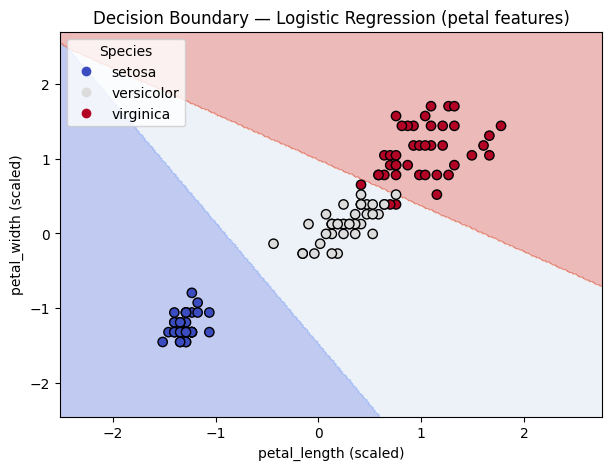

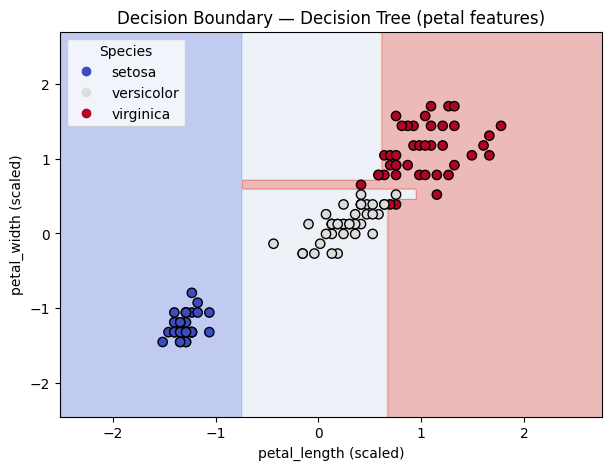

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

# ------------------------------------------------------------------
# 1. LOAD DATA
# ------------------------------------------------------------------
df = pd.read_csv("iris.csv.txt")

print("Shape:", df.shape)
print(df.head())
print("\nClass counts:\n", df['species'].value_counts())
print("\nNulls:\n", df.isnull().sum())

# Encode string labels -> integers
le = LabelEncoder()
df['target'] = le.fit_transform(df['species'])
class_names = le.classes_          # ['setosa','versicolor','virginica']

# ------------------------------------------------------------------
# 2. EXPLORATORY PAIRPLOT
# ------------------------------------------------------------------
sns.pairplot(df.drop(columns='target'), hue='species', palette='husl', corner=True)
plt.suptitle("Iris Pairplot", y=1.02)
plt.show()

# Correlation heatmap (bonus)
plt.figure(figsize=(6,4))
sns.heatmap(df.drop(columns=['species','target']).corr(), annot=True, cmap='coolwarm')
plt.title("Feature Correlation")
plt.show()

# ------------------------------------------------------------------
# 3. TRAIN / TEST SPLIT (80/20) + STANDARD SCALING
# ------------------------------------------------------------------
feature_cols = ['sepal_length','sepal_width','petal_length','petal_width']
X = df[feature_cols].values
y = df['target'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit ONLY on train
X_test_s  = scaler.transform(X_test)        # transform test with train stats

# ------------------------------------------------------------------
# 4. TRAIN & BENCHMARK MODELS
# ------------------------------------------------------------------
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree":       DecisionTreeClassifier(random_state=42)
}

results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train_s, y_train)
    y_pred = model.predict(X_test_s)
    predictions[name] = y_pred

    results.append({
        "Model":     name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average='macro'),
        "Recall":    recall_score(y_test, y_pred, average='macro'),
        "F1-Score":  f1_score(y_test, y_pred, average='macro')
    })

results_df = pd.DataFrame(results).round(4)
print("\n=== Benchmark Results ===")
print(results_df.to_string(index=False))

# Detailed report per class
for name, y_pred in predictions.items():
    print(f"\n--- {name} — Classification Report ---")
    print(classification_report(y_test, y_pred, target_names=class_names))

# ------------------------------------------------------------------
# 5. CONFUSION MATRIX HEATMAPS (side-by-side)
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(f"Confusion Matrix — {name}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# 6. DECISION BOUNDARY (2D projection using 2 most important features)
# ------------------------------------------------------------------
# Use petal_length & petal_width — they separate classes best.
feat_idx = [2, 3]
X2_train = X_train_s[:, feat_idx]
X2_test  = X_test_s[:, feat_idx]

for name, model_cls in [("Logistic Regression", LogisticRegression(max_iter=1000, random_state=42)),
                        ("Decision Tree", DecisionTreeClassifier(random_state=42))]:
    m = model_cls
    m.fit(X2_train, y_train)

    x_min, x_max = X2_train[:,0].min() - 1, X2_train[:,0].max() + 1
    y_min, y_max = X2_train[:,1].min() - 1, X2_train[:,1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))
    Z = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, Z, alpha=0.35, cmap=plt.cm.coolwarm)
    scatter = plt.scatter(X2_train[:,0], X2_train[:,1],
                          c=y_train, edgecolor='k', cmap=plt.cm.coolwarm, s=45)
    plt.xlabel("petal_length (scaled)")
    plt.ylabel("petal_width (scaled)")
    plt.title(f"Decision Boundary — {name} (petal features)")
    plt.legend(handles=scatter.legend_elements()[0],
               labels=list(class_names), title="Species")
    plt.show()

Task 2

In [7]:
from google.colab import files
uploaded = files.upload()

Saving task2.csv.txt to task2.csv.txt


Missing values per column:
 longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


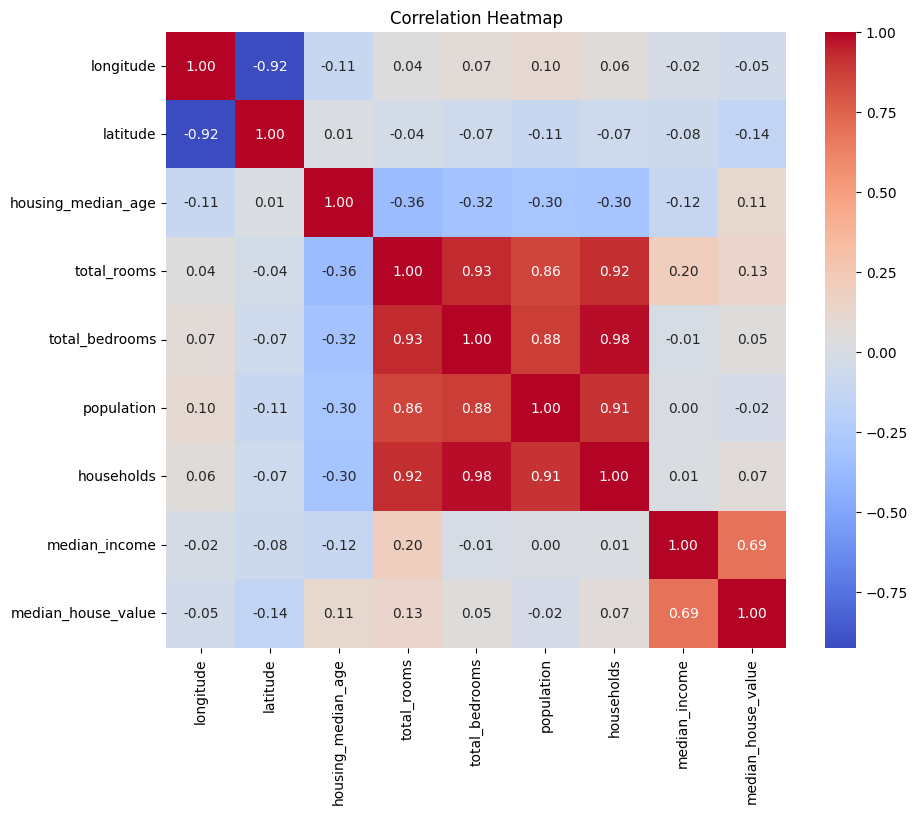


Created interaction feature: 'RoomsPerPerson'

Training models and tuning hyperparameters...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.135e+12, tolerance: 2.207e+10
  model = cd_fast.enet_coordinate_descent(



=== Benchmark Results ===
                  Model Best Alpha       RMSE        MAE     R²
OLS (Linear Regression)        N/A 69209.4176 49925.0487 0.6345
             Ridge (L2)        0.1 69210.2370 49925.9509 0.6345
             Lasso (L1)        0.1 69209.5155 49925.1757 0.6345


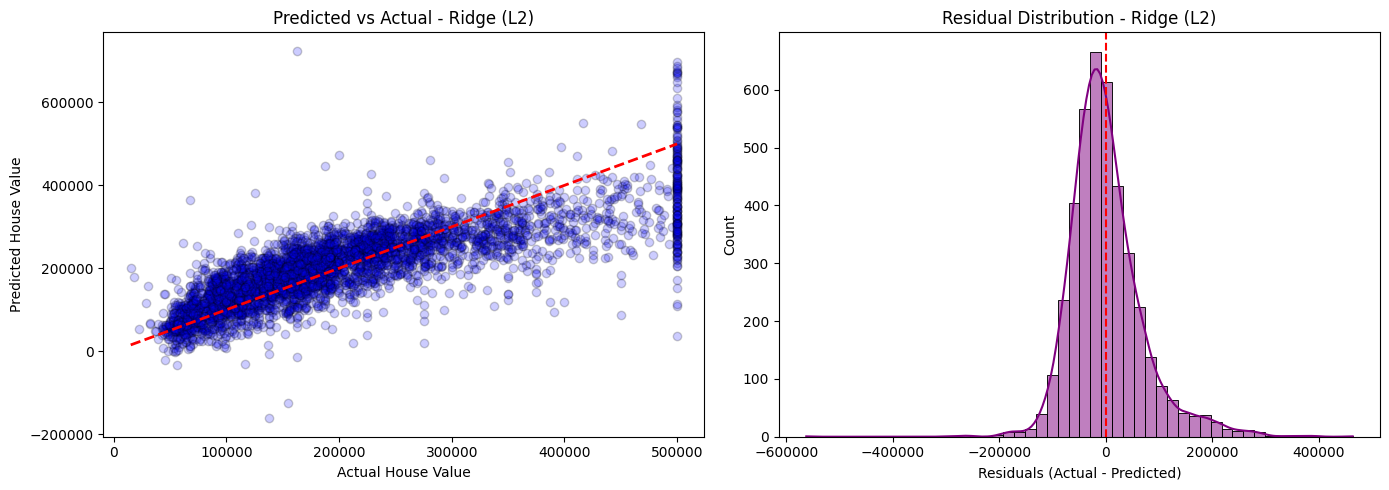

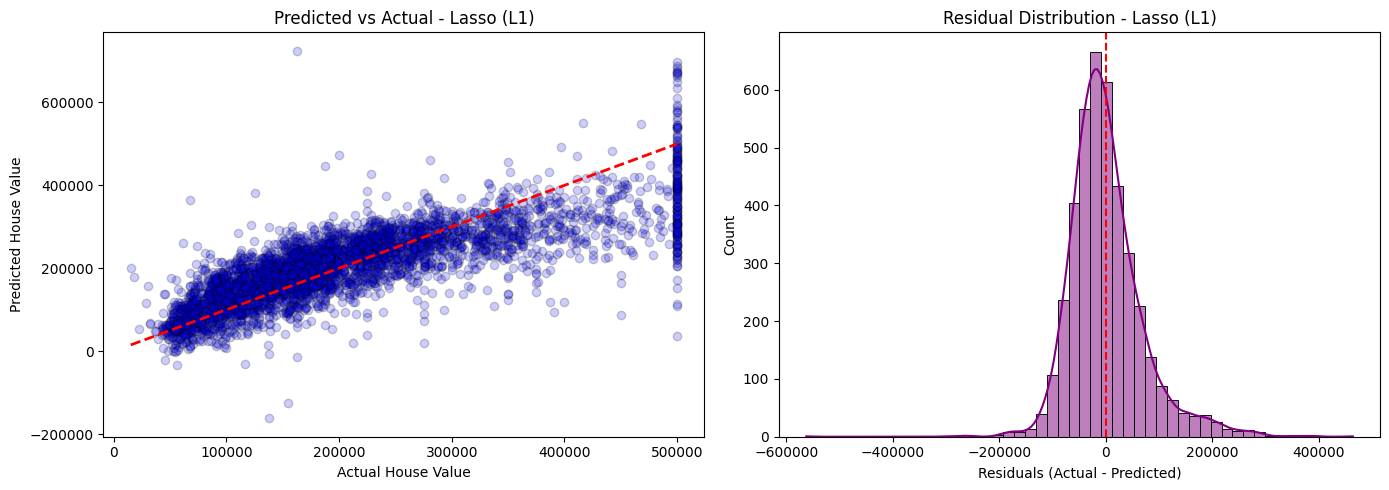

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ------------------------------------------------------------------
# 1. LOAD DATA
# ------------------------------------------------------------------
# Make sure your file is named exactly "task2.csv" (no .txt at the end)
df = pd.read_csv("task2.csv.txt")
TARGET_COL = 'median_house_value'  # <-- Updated to match your CSV

# Check for missing values (you have some in total_bedrooms!)
print("Missing values per column:\n", df.isnull().sum())

# Correlation heatmap (only numeric to avoid string error)
plt.figure(figsize=(10, 8))
sns.heatmap(df.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

# ------------------------------------------------------------------
# 2. FEATURE ENGINEERING (Interaction Features)
# ------------------------------------------------------------------
# Create RoomsPerPerson based on your column names
df['RoomsPerPerson'] = df['total_rooms'] / df['population']
print("\nCreated interaction feature: 'RoomsPerPerson'")

# ------------------------------------------------------------------
# 3. TRAIN/TEST SPLIT
# ------------------------------------------------------------------
X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ------------------------------------------------------------------
# 4. PREPROCESSING PIPELINE
# ------------------------------------------------------------------
# Get column names dynamically from your CSV
numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X.select_dtypes(exclude=[np.number]).columns.tolist()

# Numeric: Fill missing with median -> Scale
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical: Fill missing with mode -> One-Hot Encode (for ocean_proximity)
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine transformers
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# ------------------------------------------------------------------
# 5. MODEL TRAINING & HYPERPARAMETER TUNING
# ------------------------------------------------------------------
models = {
    "OLS (Linear Regression)": {
        "model": LinearRegression(),
        "params": {}
    },
    "Ridge (L2)": {
        "model": Ridge(random_state=42),
        "params": {'model__alpha': [0.1, 1.0, 10.0, 100.0]}
    },
    "Lasso (L1)": {
        "model": Lasso(random_state=42, max_iter=10000),
        "params": {'model__alpha': [0.001, 0.01, 0.1, 1.0]}
    }
}

results = []
best_models = {}

print("\nTraining models and tuning hyperparameters...")
for name, config in models.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', config['model'])
    ])

    if config['params']:
        # 3-fold CV for speed. Change to cv=5 if you have time.
        grid = GridSearchCV(pipe, config['params'], cv=3, scoring='neg_root_mean_squared_error', n_jobs=-1)
        grid.fit(X_train, y_train)
        best_model = grid.best_estimator_
        best_alpha = grid.best_params_.get('model__alpha', 'N/A')
    else:
        pipe.fit(X_train, y_train)
        best_model = pipe
        best_alpha = 'N/A'

    best_models[name] = best_model

    y_pred = best_model.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "Best Alpha": best_alpha,
        "RMSE": rmse,
        "MAE": mae,
        "R²": r2
    })

results_df = pd.DataFrame(results)
print("\n=== Benchmark Results ===")
print(results_df.round(4).to_string(index=False))

# ------------------------------------------------------------------
# 6. VISUALIZATIONS
# ------------------------------------------------------------------
for name in ["Ridge (L2)", "Lasso (L1)"]:
    model = best_models[name]
    y_pred = model.predict(X_test)
    residuals = y_test - y_pred

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Predicted vs Actual
    axes[0].scatter(y_test, y_pred, alpha=0.2, color='blue', edgecolor='k')
    axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    axes[0].set_xlabel("Actual House Value")
    axes[0].set_ylabel("Predicted House Value")
    axes[0].set_title(f"Predicted vs Actual - {name}")

    # Residual Distribution
    sns.histplot(residuals, kde=True, ax=axes[1], color='purple', bins=50)
    axes[1].axvline(x=0, color='red', linestyle='--')
    axes[1].set_xlabel("Residuals (Actual - Predicted)")
    axes[1].set_title(f"Residual Distribution - {name}")

    plt.tight_layout()
    plt.show()

Task3

In [13]:
from google.colab import files
uploaded = files.upload()

Saving task3.csv.txt to task3.csv.txt


Data Shape: (7043, 20)

Missing values remaining:
 0

Training Random Forest with Cross-Validation...
RF CV ROC-AUC: 0.8151 ± 0.0110

Training XGBoost with Cross-Validation...
XGB CV ROC-AUC: 0.8252 ± 0.0086

Fitting models on the full training set...


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [08:31:50] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


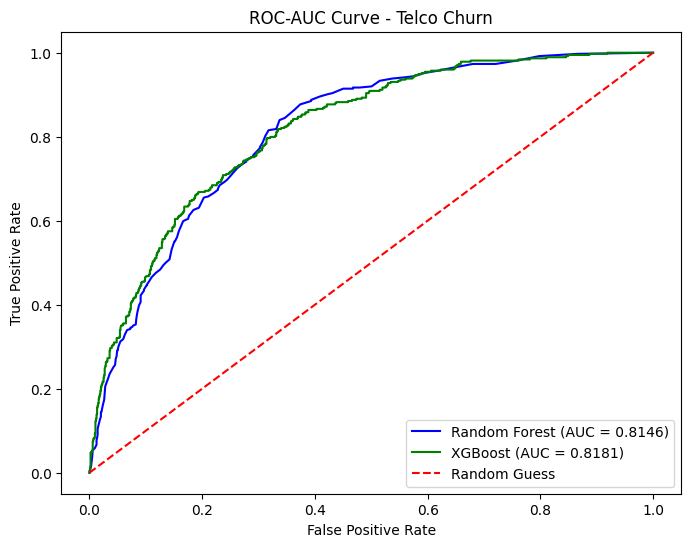

/tmp/ipykernel_8615/112263490.py:136: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='viridis')


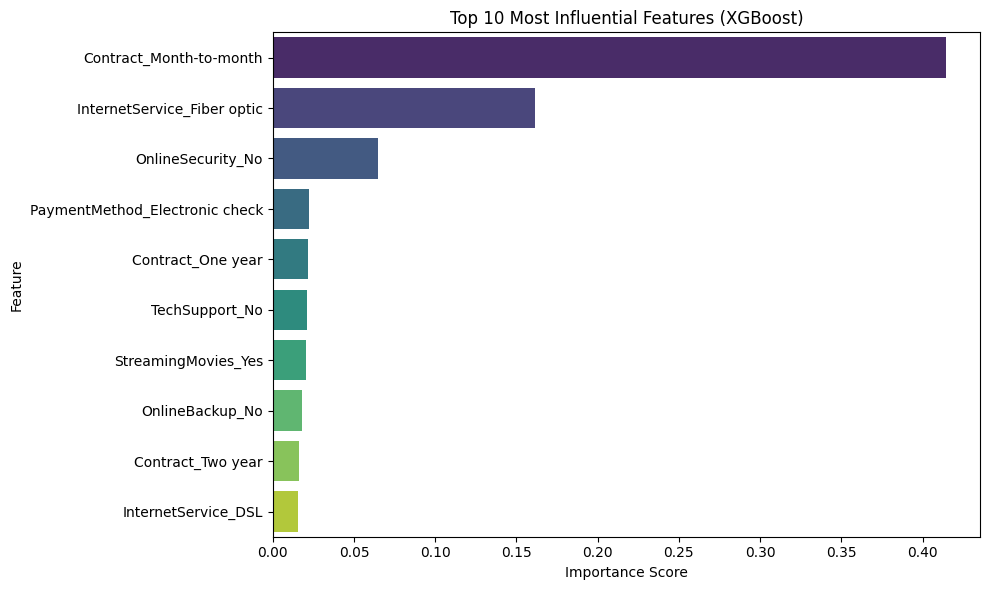

In [14]:
# If you haven't installed these yet, run this first:
# !pip install imbalanced-learn xgboost

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, roc_curve, classification_report, confusion_matrix

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# ------------------------------------------------------------------
# 1. LOAD & CLEAN DATA
# ------------------------------------------------------------------
# Load the file
df = pd.read_csv("task3.csv.txt")

# Fix TotalCharges: It has blank spaces (" ") which prevent pandas from reading it as a float
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
# Fill missing TotalCharges with the median
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# Drop customerID as it is irrelevant for modeling
df = df.drop(columns=['customerID'])

# Convert target Churn to binary (Yes = 1, No = 0)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print("Data Shape:", df.shape)
print("\nMissing values remaining:\n", df.isnull().sum().sum())

# ------------------------------------------------------------------
# 2. TRAIN/TEST SPLIT
# ------------------------------------------------------------------
X = df.drop(columns=['Churn'])
y = df['Churn']

# Stratified split to maintain class ratio
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# ------------------------------------------------------------------
# 3. PREPROCESSING PIPELINE
# ------------------------------------------------------------------
# Separate numeric and categorical columns
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

# Create transformers
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

# ------------------------------------------------------------------
# 4. MODEL TRAINING (WITH SMOTE & CROSS-VALIDATION)
# ------------------------------------------------------------------
# We use ImbPipeline to ensure SMOTE is ONLY applied to the training folds,
# preventing data leakage during cross-validation.

# Define the pipelines
rf_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])

xgb_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42))
])

# Evaluate with 5-Fold Stratified Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("\nTraining Random Forest with Cross-Validation...")
rf_cv_scores = cross_val_score(rf_pipeline, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
print(f"RF CV ROC-AUC: {rf_cv_scores.mean():.4f} ± {rf_cv_scores.std():.4f}")

print("\nTraining XGBoost with Cross-Validation...")
xgb_cv_scores = cross_val_score(xgb_pipeline, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
print(f"XGB CV ROC-AUC: {xgb_cv_scores.mean():.4f} ± {xgb_cv_scores.std():.4f}")

# Fit the models on the full training set
print("\nFitting models on the full training set...")
rf_pipeline.fit(X_train, y_train)
xgb_pipeline.fit(X_train, y_train)

# ------------------------------------------------------------------
# 5. PLOT ROC-AUC CURVES
# ------------------------------------------------------------------
# Get probabilities
rf_probs = rf_pipeline.predict_proba(X_test)[:, 1]
xgb_probs = xgb_pipeline.predict_proba(X_test)[:, 1]

# Calculate AUC scores
rf_auc = roc_auc_score(y_test, rf_probs)
xgb_auc = roc_auc_score(y_test, xgb_probs)

plt.figure(figsize=(8, 6))
plt.plot(*roc_curve(y_test, rf_probs)[:2], label=f'Random Forest (AUC = {rf_auc:.4f})', color='blue')
plt.plot(*roc_curve(y_test, xgb_probs)[:2], label=f'XGBoost (AUC = {xgb_auc:.4f})', color='green')
plt.plot([0, 1], [0, 1], 'r--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve - Telco Churn')
plt.legend(loc='lower right')
plt.show()

# ------------------------------------------------------------------
# 6. EXTRACT TOP 10 FEATURE IMPORTANCES (XGBoost)
# ------------------------------------------------------------------
# Get feature names after OneHotEncoding
cat_encoder = xgb_pipeline.named_steps['preprocessor'].named_transformers_['cat']
encoded_cat_features = cat_encoder.get_feature_names_out(categorical_features)
all_features = numeric_features + list(encoded_cat_features)

# Get feature importances from the trained XGBoost classifier
importances = xgb_pipeline.named_steps['classifier'].feature_importances_

# Create a DataFrame for plotting
feature_imp_df = pd.DataFrame({'Feature': all_features, 'Importance': importances})
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False).head(10)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='viridis')
plt.title('Top 10 Most Influential Features (XGBoost)')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

Task3

In [15]:
from google.colab import files
uploaded = files.upload()

Saving sentiment_reviews.csv to sentiment_reviews.csv


In [16]:
!pip install nltk scikit-learn pandas

In [18]:
import pandas as pd
import numpy as np
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score
from sklearn.pipeline import Pipeline

# nltk.download('punkt')
# nltk.download('punkt_tab')
# nltk.download('stopwords')
# nltk.download('wordnet')

# 1. LOAD DATA
df = pd.read_csv("sentiment_reviews.csv")

# 2. PREPROCESS
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text = re.sub(r'[^a-z\s]', '', text)
    tokens = word_tokenize(text)
    cleaned_tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return " ".join(cleaned_tokens)

df['clean_text'] = df['review_text'].apply(preprocess_text)

# 3. SPLIT (Removed stratify)
X = df['clean_text']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# 4. PIPELINES & TRAINING
nb_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000)),
    ('clf', MultinomialNB())
])

lr_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000)),
    ('clf', LogisticRegression(random_state=42, max_iter=1000))
])

nb_pipeline.fit(X_train, y_train)
lr_pipeline.fit(X_train, y_train)

# 5. EVALUATE
print("\n=== Multinomial Naive Bayes Results ===")
print(f"Accuracy: {accuracy_score(y_test, nb_pipeline.predict(X_test)):.4f}")
print(classification_report(y_test, nb_pipeline.predict(X_test), zero_division=0))

print("\n=== Logistic Regression Results ===")
print(f"Accuracy: {accuracy_score(y_test, lr_pipeline.predict(X_test)):.4f}")
print(classification_report(y_test, lr_pipeline.predict(X_test), zero_division=0))

# 6. LIVE PREDICTION
def predict_sentiment(user_input):
    cleaned_input = preprocess_text(user_input)
    nb_result = nb_pipeline.predict([cleaned_input])[0]
    lr_result = lr_pipeline.predict([cleaned_input])[0]

    print(f"\nInput: '{user_input}'")
    print(f"-> Naive Bayes:      {nb_result.upper()}")
    print(f"-> Logistic Regression: {lr_result.upper()}")
    print("-" * 50)

# 7. TEST
print("\n--- Testing Custom Input ---")
predict_sentiment("I absolutely love this product, it is fantastic!")
predict_sentiment("This is the worst purchase I have ever made. Total garbage.")
predict_sentiment("It's okay, not great but not terrible.")


=== Multinomial Naive Bayes Results ===
Accuracy: 0.3333
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         2
    positive       0.33      1.00      0.50         1

    accuracy                           0.33         3
   macro avg       0.17      0.50      0.25         3
weighted avg       0.11      0.33      0.17         3


=== Logistic Regression Results ===
Accuracy: 0.3333
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         2
    positive       0.33      1.00      0.50         1

    accuracy                           0.33         3
   macro avg       0.17      0.50      0.25         3
weighted avg       0.11      0.33      0.17         3


--- Testing Custom Input ---

Input: 'I absolutely love this product, it is fantastic!'
-> Naive Bayes:      POSITIVE
-> Logistic Regression: POSITIVE
--------------------------------------------------

Input: 'This is the worst purc